###Nama: Syahira Nanda Raihanna
###NIM: 25031554199

In [ ]:
texts = df["Text_Clean"].fillna("").astype(str)
texts.head()

,Text_Clean
0,hard imagin world without light collect poetri...
1,erot new york time book review king oyster gir...
2,dan une franc de la un dan la par ã une calm p...
3,wick girl across heart word like road map repo...
4,renown historian come groundbreak narr creatio...


In [ ]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

vectorizer = TfidfVectorizer()
tfidf_matrix = vectorizer.fit_transform(texts)

cosine_sim = cosine_similarity(tfidf_matrix)

print(cosine_sim[:5, :5].round(2))

[[1.   0.01 0.   0.01 0.01]
 [0.01 1.   0.   0.01 0.02]
 [0.   0.   1.   0.01 0.  ]
 [0.01 0.01 0.01 1.   0.06]
 [0.01 0.02 0.   0.06 1.  ]]


In [ ]:
import pandas as pd

similarity_df = pd.DataFrame(
    cosine_sim,
    index=df.index,
    columns=df.index
)

similarity_df.iloc[:10, :10].round(2)

,0,1,2,3,4,5,6,7,8,9
0,1.00,0.01,0.00,0.01,0.01,0.00,0.03,0.05,0.03,0.06
1,0.01,1.00,0.00,0.01,0.02,0.06,0.03,0.03,0.01,0.03
2,0.00,0.00,1.00,0.01,0.00,0.00,0.00,0.00,0.01,0.00
3,0.01,0.01,0.01,1.00,0.06,0.02,0.02,0.03,0.02,0.03
4,0.01,0.02,0.00,0.06,1.00,0.00,0.03,0.05,0.02,0.06
5,0.00,0.06,0.00,0.02,0.00,1.00,0.01,0.05,0.01,0.06
6,0.03,0.03,0.00,0.02,0.03,0.01,1.00,0.03,0.04,0.03
7,0.05,0.03,0.00,0.03,0.05,0.05,0.03,1.00,0.05,0.05
8,0.03,0.01,0.01,0.02,0.02,0.01,0.04,0.05,1.00,0.04
9,0.06,0.03,0.00,0.03,0.06,0.06,0.03,0.05,0.04,1.00


In [ ]:
import numpy as np

idx = 0
top_books = np.argsort(cosine_sim[idx])[::-1][1:6]

for i in top_books:
    print("Indeks buku:", i)
    print("Similarity:", round(cosine_sim[idx][i], 3))
    print("Deskripsi:", texts.iloc[i][:200], "\n")

Indeks buku: 513
Similarity: 0.108
Deskripsi: donât need geniu need thatâ messag austin young writer artist know creativ everywher creativ everyon manifesto digit age steal like artist guid whose posit messag graphic look illustr exercis exam 

Indeks buku: 220
Similarity: 0.105
Deskripsi: kind creativ everyon creativ core everyon order thrive need nurtur that whole creativ go help craft book rather fun book fill differ type unusu thoughtprovok activ exercis use ignit creativ spark some 

Indeks buku: 269
Similarity: 0.089
Deskripsi: salt journey warmth sharp collect poetri explor realiti multipl ident languag life pain self commun heal celebr love 

Indeks buku: 384
Similarity: 0.086
Deskripsi: two extraordinari red hair wrong cloth stand behind turn head lie besid wake make everyon els seem never good know shell love song play laugh joke ever get punch line there place chest make want keep  

Indeks buku: 616
Similarity: 0.083
Deskripsi: peopl think know name reput famili know sa

In [ ]:
def jaccard_similarity(a, b):
    a, b = set(a.split()), set(b.split())
    return len(a & b) / len(a | b) if a | b else 0

In [ ]:
score = jaccard_similarity(texts.iloc[0], texts.iloc[1])

print("Jaccard Similarity:", round(score, 4))

Jaccard Similarity: 0.0115


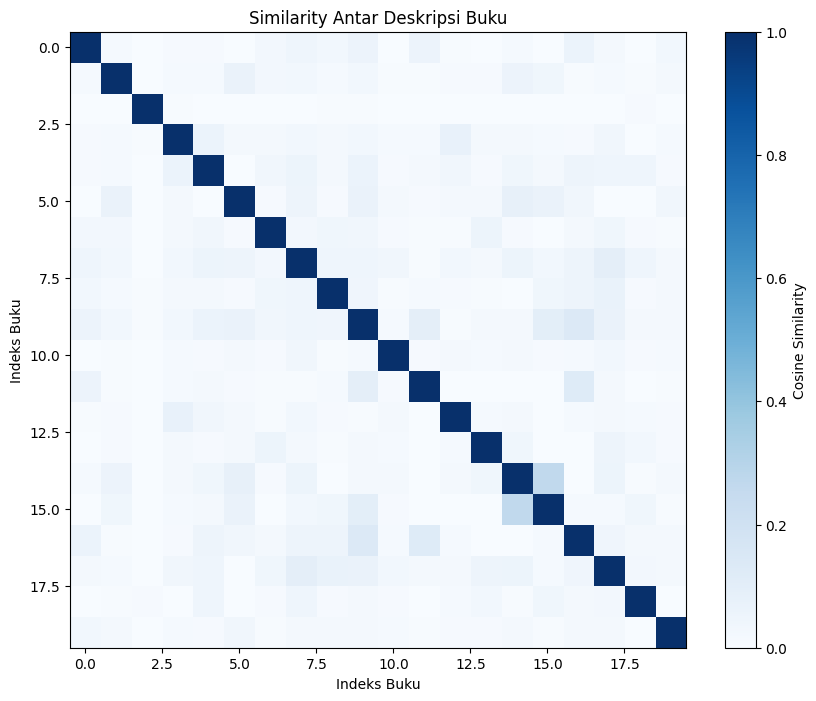

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 8))
plt.imshow(cosine_sim[:20, :20], cmap="Blues")
plt.colorbar(label="Cosine Similarity")
plt.title("Similarity Antar Deskripsi Buku")
plt.xlabel("Indeks Buku")
plt.ylabel("Indeks Buku")
plt.show()

In [ ]:

print("Contoh nilai Cosine Similarity:")
print("Buku 1 dengan Buku 2:", round(cosine_sim[0][1], 4))
print("Buku 1 dengan Buku 3:", round(cosine_sim[0][2], 4))

print("\nInterpretasi:")
print("Nilai mendekati 1 menunjukkan deskripsi semakin mirip.")
print("Nilai mendekati 0 menunjukkan deskripsi kurang mirip.")


Contoh nilai Cosine Similarity:
Buku 1 dengan Buku 2: 0.0142
Buku 1 dengan Buku 3: 0.0

Interpretasi:
Nilai mendekati 1 menunjukkan deskripsi semakin mirip.
Nilai mendekati 0 menunjukkan deskripsi kurang mirip.


In [ ]:

import numpy as np

similar_pairs = []

for i in range(len(cosine_sim)):
    for j in range(i + 1, len(cosine_sim)):
        similar_pairs.append((i, j, cosine_sim[i][j]))

similar_pairs = sorted(
    similar_pairs, key=lambda x: x[2], reverse=True
)

for i, j, score in similar_pairs[:5]:
    print(f"Buku {i} dan Buku {j}")
    print("Cosine Similarity:", round(score, 4))
    print("Deskripsi 1:", texts.iloc[i][:150])
    print("Deskripsi 2:", texts.iloc[j][:150])
    print("-" * 50)


Buku 236 dan Buku 358
Cosine Similarity: 0.9293
Deskripsi 1: fate fortun power passion take queen kingdom your curs promis marriag death destruct earn scorn fear father kingdom content follow scholarli pursuit w
Deskripsi 2: fate fortun power passion take queen kingdom youâr curs promis marriag death destruct earn scorn fear fatherâ kingdom content follow scholarli pur
--------------------------------------------------
Buku 243 dan Buku 277
Cosine Similarity: 0.7333
Deskripsi 1: famili hit road authorillustr jeff latest instal phenomen bestsel diari kid seri
Deskripsi 2: latest instal phenomen bestsel diari kid seri authorillustr jeff bring seri back root start new school year face challeng never imagin
--------------------------------------------------
Buku 575 dan Buku 632
Cosine Similarity: 0.6744
Deskripsi 1: light ace student great prospect he bore mind chang find death note notebook drop rogu shinigami death god human whose name written notebook die light
Deskripsi 2: light a